# Solve Inverse Problems - Simulations

Let's try out the inverse module on some simulations.


## 🧪 - Experiment setup
- `fwd`: Forward solution
- `ave`: Measurements
- `ncov`: Noise covariance
- `eig`: Eigenvectors and eigenvalues of the Connectome Lacplacian.
- `gt`: Ground truth

In [5]:
# imports
import mindmap as mm
import mne

# readers
dm = mm.io.TutoManager("../../config.yml")
sr = dm.get_subject("simf-10")

# data
fwd = sr.load("fwd")
ave = sr.load("ave", task="rest", run="11")
ncov = sr.load("cov", task="rest", run="11")
eig = sr.load("eig")
gt = sr.load("gt", task="rest", run="11")

## 🧬 - Data Processing
Apply inverse solver.

In [23]:
ave.info["projs"][0]["data"]["data"]

array([[0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07018624, 0.07018624,
        0.07018624, 0.07018624, 0.07018624, 0.07

In [11]:
# mindmap's inverse solution
inv = mm.analysis.inverse.MNE(
    forward = fwd,
    noise_cov = ncov,
    depth = 0.0,
    snr = 3.0,
    noise_norm = None,
    nave = ave.nave,
)

sol = inv.solve(ave)

# MNE-pythons' inverse solution
inv_mne = mne.minimum_norm.make_inverse_operator(
    info = ave.info,
    forward = fwd,
    noise_cov = ncov,
    fixed = True,
    depth = 0.0,
)

snr = 3.0
stc, residual = mne.minimum_norm.apply_inverse(
    ave,
    inv_mne,
    lambda2 = 1.0 / snr**2,
    method = "MNE",
    pick_ori = None,
    return_residual = True,
    verbose = True,
)

Computing inverse operator with 203 channels.
    203 out of 203 channels remain after picking
Selected 203 channels
    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 7.8e-13 (2.2e-16 eps * 203 dim * 17  max singular value)
    Estimated rank (eeg): 202
    EEG: rank 202 computed from 203 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
Creating the source covariance matrix
Adjusting source covariance matrix.
Computing SVD of whitened and weighted lead field matrix.
    largest singular value = 2.72789
    scaling factor to adjust the trace = 6.67492e+19 (nchan = 203 nzero = 1)
Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 20
    Cr

## 📊 - Visualization

Measurements - timeseries

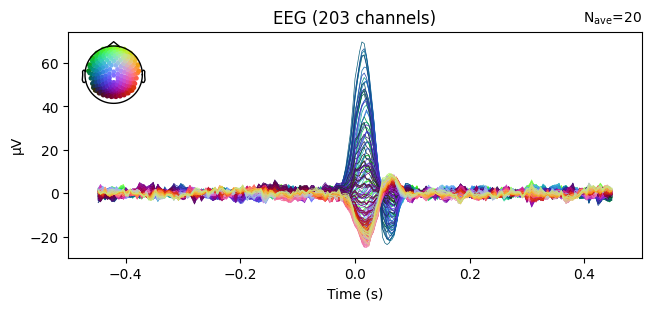

In [12]:
_ = ave.plot(xlim=(-0.5, 0.5))

Measurements - topographies

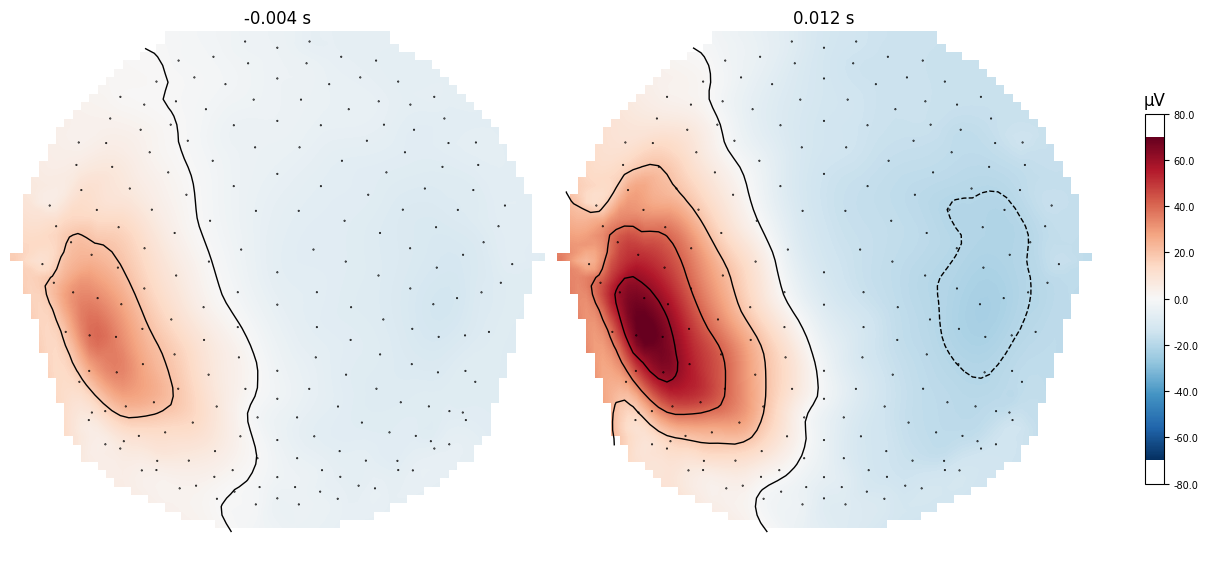

In [13]:
hrp = mm.analysis.eeg.get_rising_phase(ave, ratio=0.5)    # half rising phase
pp  = mm.analysis.eeg.get_rising_phase(ave, ratio=1)      # peak phase

_ = ave.plot_topomap(times=[hrp, pp], size=4, extrapolate="local", outlines=None)

Source reconstruction

In [14]:
mm.viz.plot_source_estimate(
    source_space = fwd["src"],
    timeseries = [sol, stc],
    ts_params={"normalize":True, "absolute":True}
).show()

Widget(value='<iframe src="http://localhost:42501/index.html?ui=P_0x7cabf6df8210_0&reconnect=auto" class="pyvi…

In [15]:
fwd.get("proj", [])

[]

## ⚙️ Apply a source reconstruction method

**Available methods**:

- <font color=gray>MNE</font>: Assumes independent gaussian distributed sources. Uses depth weighting to correct for depth bias.
- <font color=gray>sLORETA</font>: Assumes independent gaussian distributed sources. Applies a post-hoc standardization.
- <font color=gray>dSMP</font>: ...
- <font color=gray>beamformer</font>: ...
- <font color=gray>CSET</font>: Assumes sparse connectome spectrum ($\hat{\mathbf s} = \mathbf U^\intercal \mathbf s \rightarrow$ sparse).
- <font color=gray>wCSET</font>: Assumes independent gaussian distributed connectome spectrum with components weighted by spatial frequency.

🎚️ **<font color=pink>Inverse</font>**:
- `method`: ["MNE", "sLORETA", "dSMP", "beamformer", "CSET", "wCSET"]
- `lam`: Regularizer parameter
- `depth`: Depth weighting exponent
- `relax`: Harmonic weight relaxation

In [15]:
# ------------ Parameters -------------
# method
method = "wcset"

# common parameters
depth = 0
lam   = 1

# wcset parameters
harm = 0.7

# -------------------------------------

if method.lower() == "sloreta":
    ncov = mne.make_ad_hoc_cov(data["ave"].info, std={"eeg":1})

    inverse = mne.minimum_norm.make_inverse_operator(
        info      = data["ave"].info,
        forward   = data["fwd"],
        noise_cov = ncov,
        fixed     = True,
        depth     = depth,               # depth weighting doesn't do anything in sLORETA
        verbose   = "warning",
    )

    stc = mne.minimum_norm.apply_inverse(
        evoked           = data["ave"],
        inverse_operator = inverse,
        lambda2          = lam,
        method           = "sLORETA",
        verbose          = "warning",
    )

elif method.lower() == "cset":
    inverse = mm.inverse.CSET(
        info      = data["ave"].info,
        leadfield = data["fwd"],
        eig_vec   = data["eig"]["vec"],
        noise_cov = None,
        depth     = depth,
    )

    stc = inverse(data["ave"])

elif method.lower() == "wcset":
    # compute wCSET solution
    inverse = mm.inverse.wCSET(
        info            = data["ave"].info,
        leadfield       = data["fwd"],
        noise_cov       = None,
        eig_vec         = data["eig"]["vec"],
        eig_val         = data["eig"]["val"],
        depth           = depth,
        harm            = harm,
    )

    stc = inverse(data["ave"], lam=lam)

else:
    raise ValueError(f"Unknown method '{method}'")

📊 **Source Image**

In [16]:
print(f"halr rising phase: {hrp} [s]")
print(f"peak phase: {pp} [s]")

mm.viz.plot_source_estimate(data["fwd"]["src"], stc, ts_params={"absolute":True}).show()

halr rising phase: 1.915 [s]
peak phase: 1.94 [s]


Widget(value='<iframe src="http://localhost:37361/index.html?ui=P_0x732fc1f965d0_0&reconnect=auto" class="pyvi…

In [17]:
spec = data["eig"]["vec"].T@stc.data
mm.viz.plot_spectrum(spec, stc.times)

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 4961 is different from 7465)

In [32]:
# ------------- Parameters ---------------
fconfig = "../../data/config.yml"
subject = "intra-12"
# ----------------------------------------

reader = mm.io.TutoReader(fconfig)
data   = reader(subject, "con", "eig", "src-raw")

eigvec = data["eig"]["vec"]
eigval = data["eig"]["val"]

/home/nino/Code/mindmap/data/derivatives/mindmap/sub-intra-12/src/sub-intra-12_src.fif
DATA SUMMARY
Dataset: tuto
Subject: intra-12
Task: None
Run: None
Retrieved objects:
- eig
- con
- src-raw
Missing objects:


In [4]:
import seaborn as sns

def plot_eigval(eigval, subject="unknown"):
    """
    Plot eigenvalues.
    """
    ax = sns.lineplot(eigval)
    ax.set_title(f"Eigenvalues sub-{subject}")
    ax.set_xlabel("Harmonic index")
    ax.set_ylabel("Eigenvalue")
    

/home/nino/Code/mindmap/data/derivatives/mindmap/sub-intra-12/src/sub-intra-12_src.fif
DATA SUMMARY
Dataset: tuto
Subject: intra-12
Task: None
Run: None
Retrieved objects:
- src-raw
- con
- eig
Missing objects:


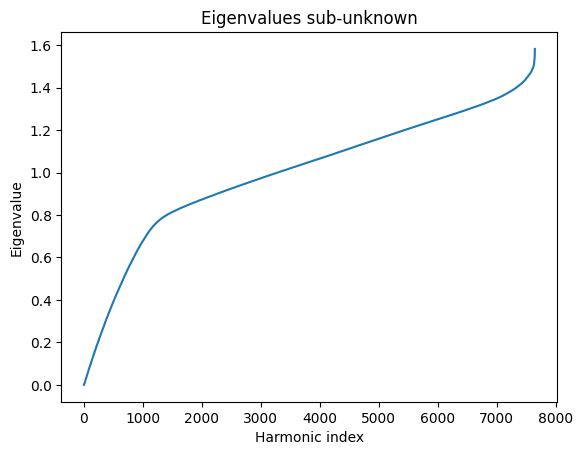

In [5]:
import mindmap as mm

# ------------- Parameters ---------------
fconfig = "../../data/config.yml"
subject = "intra-12"
# ----------------------------------------

reader = mm.io.TutoReader(fconfig)
data   = reader(subject, "con", "eig", "src-raw")

eigvec = data["eig"]["vec"]
eigval = data["eig"]["val"]

plot_eigval(eigval)

In [17]:
pv.set_jupyter_backend("none")
pv.global_theme.jupyter_backend = None

pl = pv.Plotter()
pl.add_mesh(pv.Sphere())
pl.show()